# 3 — The published intervention, and ours, on 8SGE

**What this notebook establishes.** Boltz-Perturb's TCP moves 8SGE from 1 draw in
20 to 11, and it does so for a reason their paper does not state: the perturbation
is **redrawn at every step**. Held fixed at the same magnitude and the same
schedule, the identical intervention reaches 7 and damages the structures it
reaches. Our own ablation is the held-fixed kind.

**What it needs.** `numpy`, `matplotlib`, this repository, and
`data/tcp/arm_poses.csv`. No GPU.

**The five arms** differ one factor at a time and share seed 42 and every Boltz
flag, so the per-pose atom-noise draws match across arms:

| arm | what it does |
| --- | --- |
| `base_noinj` | nothing |
| `slig_noinj` | ours: ligand rows of `s_trunk` replaced with matched Gaussian noise, drawn once |
| `tcp_c11` | theirs: `s` perturbed over steps 80–159, direction redrawn every step |
| `tcp_c11_frozen` | C11 with the direction drawn **once** and reused |
| `tcp_c10` | C11's magnitude spread over the whole trajectory |


In [1]:
import csv, sys, pathlib

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import matplotlib.pyplot as plt

from cofolding_tts import basin

ARMS = ['base_noinj', 'slig_noinj', 'tcp_c11', 'tcp_c11_frozen', 'tcp_c10']
LABEL = {'base_noinj': 'no intervention', 'slig_noinj': 'ours, s_trunk ligand rows',
         'tcp_c11': 'TCP C11, redrawn', 'tcp_c11_frozen': 'TCP C11, frozen',
         'tcp_c10': 'TCP C10, whole run'}

poses = {a: {'rmsd': [], 'torsion': [], 'lddt': []} for a in ARMS}
for r in csv.DictReader((ROOT / 'data' / 'tcp' / 'arm_poses.csv').open()):
    poses[r['arm']]['rmsd'].append(float(r['ligand_rmsd_angstrom']))
    poses[r['arm']]['torsion'].append(float(r['final_torsion_deg']))
    poses[r['arm']]['lddt'].append(float(r['lddt_pli']))
poses = {a: {k: np.array(v) for k, v in d.items()} for a, d in poses.items()}
print({a: len(d['rmsd']) for a, d in poses.items()})

{'base_noinj': 20, 'slig_noinj': 20, 'tcp_c11': 20, 'tcp_c11_frozen': 20, 'tcp_c10': 20}


## Scoring the arms

The basin test is `cofolding_tts.basin`, the same criterion notebook 1 used: within
40° of a measured centre and nearer to it than to the other, with everything else
counted as **neither** rather than folded into a rate. `broken` counts poses
below lDDT-PLI 0.5: a torsion in the right place inside a damaged structure is not
a rescue, and reporting the basin rate alone would hide that.


In [2]:
print(f"{'arm':>16}  {'correct':>7}  {'wrong':>5}  {'neither':>7}  {'<2 A':>5}  "
      f"{'med RMSD':>9}  {'lDDT':>6}  {'broken':>6}  {'circSD':>7}")
summary = {}
for arm in ARMS:
    d = poses[arm]
    label = basin.classify(d['torsion'])
    ok = label == 'correct'
    n = basin.counts(d['torsion'])
    summary[arm] = dict(n, under2=int((d['rmsd'] < 2).sum()),
                        med=np.median(d['rmsd'][ok]) if ok.any() else float('nan'),
                        lddt=d['lddt'].mean(),
                        broken=int((d['lddt'] < 0.5).sum()),
                        sd=basin.circular_sd(d['torsion'][ok]) if ok.sum() > 1 else 0.0)
    s = summary[arm]
    print(f"{arm:>16}  {s['correct']:4d}/20  {s['wrong']:5d}  {s['neither']:7d}  "
          f"{s['under2']:5d}  {s['med']:8.2f} A  {s['lddt']:6.3f}  {s['broken']:6d}  {s['sd']:6.1f} deg")

             arm  correct  wrong  neither   <2 A   med RMSD    lDDT  broken   circSD
      base_noinj     1/20     19        0      1      0.92 A   0.635       0     0.0 deg
      slig_noinj     9/20      8        3      4      2.98 A   0.710       0     4.5 deg
         tcp_c11    11/20      7        2     10      1.25 A   0.718       2    10.3 deg
  tcp_c11_frozen     7/20     11        2      3      2.47 A   0.578       4    12.5 deg
         tcp_c10     5/20      7        8      0      2.85 A   0.494       8    28.6 deg


## The redraw, isolated

`tcp_c11` and `tcp_c11_frozen` are the same magnitude, the same window and the same
ψ. The only difference is whether the direction is drawn once or at every step.


In [3]:
fresh, frozen = summary['tcp_c11'], summary['tcp_c11_frozen']
print(f"basin      {fresh['correct']:>2} redrawn vs {frozen['correct']:>2} frozen")
print(f"under 2 A  {fresh['under2']:>2} redrawn vs {frozen['under2']:>2} frozen")
print(f"broken     {fresh['broken']:>2} redrawn vs {frozen['broken']:>2} frozen")
print(f"lDDT-PLI   {fresh['lddt']:.3f} redrawn vs {frozen['lddt']:.3f} frozen")
print()
print('Our own ablation draws its replacement once and re-reads it every step,')
print(f"so it is structurally the frozen kind: {summary['slig_noinj']['correct']}/20 in the basin,")
print(f"{summary['slig_noinj']['under2']} under 2 A, correct-basin median {summary['slig_noinj']['med']:.2f} A.")

basin      11 redrawn vs  7 frozen
under 2 A  10 redrawn vs  3 frozen
broken      2 redrawn vs  4 frozen
lDDT-PLI   0.718 redrawn vs 0.578 frozen

Our own ablation draws its replacement once and re-reads it every step,
so it is structurally the frozen kind: 9/20 in the basin,
4 under 2 A, correct-basin median 2.98 A.


wrote results/figures/nb03_tcp_arms.png


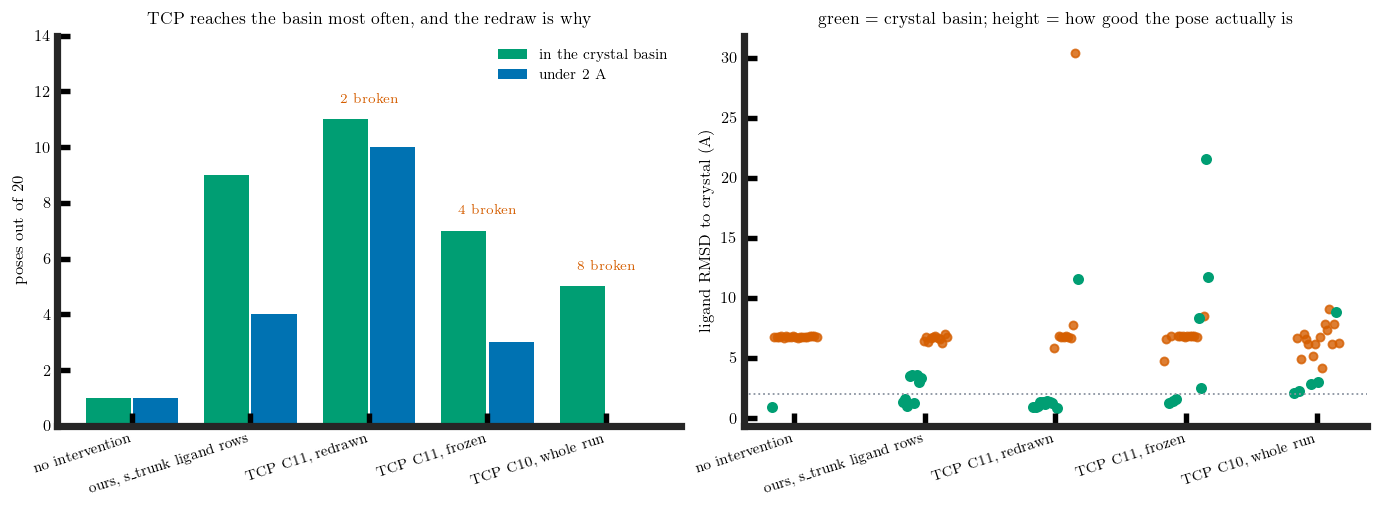

In [4]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.labelsize': 9, 'axes.titlesize': 9.5,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8.5})
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.8), dpi=130, constrained_layout=True)
GREEN, ORANGE, GREY, BLUE = '#009e73', '#d55e00', '#8a93a0', '#0072b2'
x = np.arange(len(ARMS))

ax.bar(x - 0.2, [summary[a]['correct'] for a in ARMS], 0.38, color=GREEN, label='in the crystal basin')
ax.bar(x + 0.2, [summary[a]['under2'] for a in ARMS], 0.38, color=BLUE, label='under 2 A')
for i, a in enumerate(ARMS):
    if summary[a]['broken']:
        ax.text(i, max(summary[a]['correct'], summary[a]['under2']) + 0.6,
                f"{summary[a]['broken']} broken", ha='center', fontsize=7.5, color=ORANGE)
ax.set_xticks(x); ax.set_xticklabels([LABEL[a] for a in ARMS], rotation=18, ha='right')
ax.set_ylabel('poses out of 20'); ax.set_ylim(0, 14)
ax.set_title('TCP reaches the basin most often, and the redraw is why')
ax.legend(fontsize=8, frameon=False)

for i, a in enumerate(ARMS):
    d = poses[a]
    ok = basin.classify(d['torsion']) == 'correct'
    jitter = np.linspace(-0.17, 0.17, len(d['rmsd']))
    bx.scatter(i + jitter[~ok], d['rmsd'][~ok], s=20, color=ORANGE, alpha=.8)
    bx.scatter(i + jitter[ok], d['rmsd'][ok], s=26, color=GREEN)
bx.axhline(2.0, color=GREY, lw=1.0, ls=':')
bx.set_xticks(x); bx.set_xticklabels([LABEL[a] for a in ARMS], rotation=18, ha='right')
bx.set_ylabel('ligand RMSD to crystal (A)')
bx.set_title('green = crystal basin; height = how good the pose actually is')
for a in (ax, bx):
    a.spines[['top', 'right']].set_visible(False)
out = ROOT / 'results' / 'figures' / 'nb03_tcp_arms.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## The other three systems are not run

Everything above is 8SGE. TCP has **not** been run on 7FTM, 8CJG or 8JJQ, and the
most important of those is 8JJQ: it is the system the model already gets right 18
times in 20, so it is where an intervention can do harm. Our ablation costs
accuracy there — 90% to 68% — and whether TCP does the same is unknown.

Running them needs a GPU, the Boltz environment from `scripts/setup_boltz.sh`, and
the inputs for those systems, which are not vendored here — only 8SGE is runnable
from a fresh clone. On 8SGE the arms are one command each:

```bash
python scripts/run_8sge.py --arm tcp        --draws 20 --python .venv-boltz/bin/python
python scripts/run_8sge.py --arm tcp-frozen --draws 20 --python .venv-boltz/bin/python
python scripts/run_8sge.py --arm tcp-c10    --draws 20 --python .venv-boltz/bin/python
python scripts/score_8sge.py --runs runs
```

Each arm is 20 draws at roughly 255 s a draw on one GPU, so about 85 minutes per
arm, per system.


In [5]:
# What is missing, stated as data rather than prose.
PLANNED = {'7ftm': 'wrong cavity, 31 A; does a conditioning perturbation reach it at all?',
           '8cjg': 'already half-right; the arm that tests whether TCP adds anything',
           '8jjq': 'HARM CONTROL: right 18/20 unperturbed; the one that can only lose'}
print(f"{'system':>7}  {'TCP arms run':>12}   why it matters")
print(f"{'8sge':>7}  {'5 of 5':>12}   done, above")
for pdb, why in PLANNED.items():
    print(f'{pdb:>7}  {"0 of 5":>12}   {why}')

 system  TCP arms run   why it matters
   8sge        5 of 5   done, above
   7ftm        0 of 5   wrong cavity, 31 A; does a conditioning perturbation reach it at all?
   8cjg        0 of 5   already half-right; the arm that tests whether TCP adds anything
   8jjq        0 of 5   HARM CONTROL: right 18/20 unperturbed; the one that can only lose


## What this fixes, and what it does not

- **Their 8SGE claim replicates** on a stock sampler, at a third of their sample
  budget and with no ranking step.
- **The redraw is the lever, not the magnitude.** This is ours, not theirs: their
  paper reports the window and the scale, not that refreshing the draw is what
  carries the effect. It also falsified our own prediction, which was that the
  88° magnitude of our replacement would beat their 30° rotation.
- **C10 is destructive, not merely weaker.** Perturbing past step 154, where the
  sampler injects no noise, is bias with nothing left to relax it.
- **None of this is generalisation.** One system, one conditioning, 20 draws an arm.
  Until the 8JJQ arm is run, nothing here says what TCP costs where the model is
  already right.
